# Figuras para el artículo, en inglés y en español

Este notebook genera las 16 figuras candidatas para el artículo en dos idiomas: en inglés en `artifacts/paper_figures/en/` y en español en `artifacts/paper_figures/es/`, las dos a 300 ppp. Cada figura se dibuja con el mismo código, los mismos datos, el mismo tamaño y la misma paleta que su versión original en `artifacts/figures/` (notebook 01) o en `artifacts/model_search/` (notebooks 05 y 06); solo cambian el idioma de los textos y el formato de los números. Las figuras originales no se tocan.

- **Datos.** Las figuras de la exploración se recalculan desde `data/raw/` con el mismo código del notebook 01. Las de los modelos se dibujan desde los archivos de `artifacts/model_search/`, sin recalcular nada. Solo las curvas precisión-recall necesitan las probabilidades de los 4 modelos registrados sobre la prueba: se predicen con los modelos exportados, igual que en la sección 8 del notebook 06, sin entrenar ni recalcular métricas.
- **Números.** En inglés, punto decimal, coma de miles y porcentaje sin espacio (`16.5%`, `82,332`); en español, coma decimal, punto de miles y porcentaje con espacio (`16,5 %`, `82.332`).
- **Nombres de los modelos.** En inglés: HistGradientBoosting, Random forest, MLP y Logistic regression (baseline); en español: HistGradientBoosting, Random forest, MLP y Regresión logística (modelo base). En inglés, las otras familias son Extra trees, Decision tree, Gaussian naive Bayes y Dummy; en español, Extra trees, Árbol de decisión, Gaussian naive Bayes y Clasificador trivial. Las figuras nunca muestran los nombres internos del código (`hist_gradient_boosting`, `mlp`...). Los tipos de ataque y las variables quedan igual.
- **Sin título general.** En IEEE el título va en la leyenda (caption) de la figura en el artículo: las imágenes no llevan título superior. Los subtítulos de cada panel sí se quedan.
- **Qué se muestra aquí.** Debajo de cada figura se ve la versión en inglés; las dos se guardan en su carpeta.

## 1. Preparar el entorno

`autoreload` recarga el código de `src/threat_detector/` si cambia mientras el notebook está abierto.

In [1]:
%load_ext autoreload
%autoreload 2

## 2. Importar la lógica del proyecto y las funciones comunes

Las rutas, los nombres de las columnas y las funciones de carga salen de `src/threat_detector/`. Aquí se definen además las funciones que comparten todas las figuras:

- `number` y `percent` escriben un número o un porcentaje en el formato de cada idioma; `axis_number` hace lo mismo con las marcas de un eje, sin cambiar dónde caen.
- `MODEL_NAMES` tiene los nombres de las 8 familias en el artículo, en cada idioma.
- `eda_style` aplica el estilo de seaborn que usa el notebook 01 (`whitegrid`) solo mientras se dibuja una figura de la exploración; las de los modelos usan el estilo de matplotlib por defecto, como en los notebooks 05 y 06.
- `save` guarda la figura en `artifacts/paper_figures/<idioma>/` a 300 ppp, con las mismas opciones de su original: las de la exploración con el borde ajustado (`bbox_inches="tight"`) y fondo blanco, y las de los modelos con el fondo de su paleta.

In [2]:
import json
from contextlib import contextmanager

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
from sklearn.metrics import average_precision_score, precision_recall_curve

from threat_detector.artifacts import load_model, predict_flows, read_model_info
from threat_detector.config import (
    MODEL_SEARCH_CSV,
    MODEL_SEARCH_DIR,
    PAPER_FIGURE_LANGUAGES,
    PAPER_FIGURES_DIR,
    ROOT,
    TEST_PER_TYPE_CSV,
    TEST_RESULTS_CSV,
)
from threat_detector.dataset import ATTACK_CAT, ATTACK_TYPES, ID_COL, TARGET, load_test, load_train
from threat_detector.ml.training import MODEL_FAMILIES, read_search_results

DPI = 300
for language in PAPER_FIGURE_LANGUAGES:
    (PAPER_FIGURES_DIR / language).mkdir(parents=True, exist_ok=True)

# Nombres de las 8 familias en el artículo; las figuras nunca muestran los nombres internos del código.
MODEL_NAMES = {
    "en": {"hist_gradient_boosting": "HistGradientBoosting", "random_forest": "Random forest", "mlp": "MLP",
           "logistic_regression": "Logistic regression (baseline)", "extra_trees": "Extra trees",
           "decision_tree": "Decision tree", "gaussian_nb": "Gaussian naive Bayes", "dummy": "Dummy"},
    "es": {"hist_gradient_boosting": "HistGradientBoosting", "random_forest": "Random forest", "mlp": "MLP",
           "logistic_regression": "Regresión logística (modelo base)", "extra_trees": "Extra trees",
           "decision_tree": "Árbol de decisión", "gaussian_nb": "Gaussian naive Bayes", "dummy": "Clasificador trivial"},
}
# Paleta de las figuras de los modelos (notebooks 05 y 06).
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"


def number(value, decimals, language):
    """value con decimals decimales y separador de miles: "82,332.5" en inglés, "82.332,5" en español."""
    text = f"{value:,.{decimals}f}"
    return text if language == "en" else text.translate(str.maketrans(",.", ".,"))


def percent(value, decimals, language):
    """value ya en porcentaje (0 a 100): "16.5%" en inglés, "16,5 %" en español."""
    return number(value, decimals, language) + ("%" if language == "en" else " %")


def signed(value, decimals, language):
    """value con signo siempre, como en las originales ("+0.0021", "-0.0527"; en español, "+0,0021")."""
    text = f"{value:+,.{decimals}f}"
    return text if language == "en" else text.translate(str.maketrans(",.", ".,"))


def axis_number(language, decimals=None):
    """Formato de las marcas de un eje; sin decimals, el valor más corto (como el formato por defecto)."""
    if decimals is None:
        def short(value):
            text = f"{value:g}"
            return text if language == "en" else text.replace(".", ",")
        return FuncFormatter(lambda value, _: short(value))
    return FuncFormatter(lambda value, _: number(value, decimals, language))


def axis_percent(language, decimals, fraction=True):
    """Marcas en porcentaje; con fraction, los valores del eje van de 0 a 1."""
    return FuncFormatter(lambda value, _: percent(value * 100 if fraction else value, decimals, language))


@contextmanager
def eda_style():
    """El estilo del notebook 01 (sns.set_theme(style="whitegrid")) solo dentro del bloque."""
    with mpl.rc_context():
        sns.set_theme(style="whitegrid")
        yield


def save(fig, name, language, eda=False):
    """Guarda la figura en artifacts/paper_figures/<language>/<name>.png a 300 ppp; muestra la versión en inglés."""
    path = PAPER_FIGURES_DIR / language / f"{name}.png"
    if eda:
        fig.savefig(path, dpi=DPI, bbox_inches="tight")
    else:
        fig.savefig(path, dpi=DPI, facecolor=SURFACE)
    if language == "en":
        display(fig)
    plt.close(fig)
    return path.relative_to(ROOT)


def save_both(draw, name, eda=False):
    """Dibuja la figura en cada idioma con draw(language) y la guarda."""
    for language in PAPER_FIGURE_LANGUAGES:
        if eda:
            with eda_style():
                fig = draw(language)
        else:
            fig = draw(language)
        print("Guardada:", save(fig, name, language, eda=eda))

## 3. Datos

- **Exploración:** las particiones de `data/raw/`, leídas con `load_train` y `load_test` (que además comprueban columnas y filas), y las mismas listas de columnas del notebook 01: 3 categóricas y 39 numéricas, 42 en total, con las que se arma el identificador de patrón de flujo idéntico.
- **Modelos:** los resultados guardados en `artifacts/model_search/`. `test_results.csv` se lee como en el notebook 06.

In [3]:
train, test = load_train(), load_test()
categorical_cols = [c for c in train.select_dtypes(include="str").columns if c != ATTACK_CAT]
numeric_cols = [c for c in train.select_dtypes(include="number").columns if c not in (ID_COL, TARGET)]
feature_cols = categorical_cols + numeric_cols
assert (len(categorical_cols), len(numeric_cols)) == (3, 39)
pattern_id = pd.util.hash_pandas_object(train[feature_cols], index=False)
ttl_cols = ["sttl", "dttl", "ct_state_ttl"]

results = pd.read_csv(TEST_RESULTS_CSV)
per_type = pd.read_csv(TEST_PER_TYPE_CSV)
search = read_search_results(MODEL_SEARCH_CSV)
gap = pd.read_csv(MODEL_SEARCH_DIR / "train_validation_gap.csv")
by_category = pd.read_csv(MODEL_SEARCH_DIR / "false_alarms_by_category.csv")
numeric_table = pd.read_csv(MODEL_SEARCH_DIR / "numeric_differences_normals.csv")
importance = pd.read_csv(MODEL_SEARCH_DIR / "global_importance.csv")
print(f"Entrenamiento: {len(train):,} flujos · prueba: {len(test):,} flujos · patrones distintos: {pattern_id.nunique():,}")

Entrenamiento: 175,341 flujos · prueba: 82,332 flujos · patrones distintos: 101,040


## 4. Exploración del dataset

### `target_distribution`: distribución de las clases en el entrenamiento

Igual que el notebook 01: a la izquierda, los flujos normales y de ataque (`label`) con su porcentaje; a la derecha, los flujos de cada `attack_cat` en escala logarítmica.

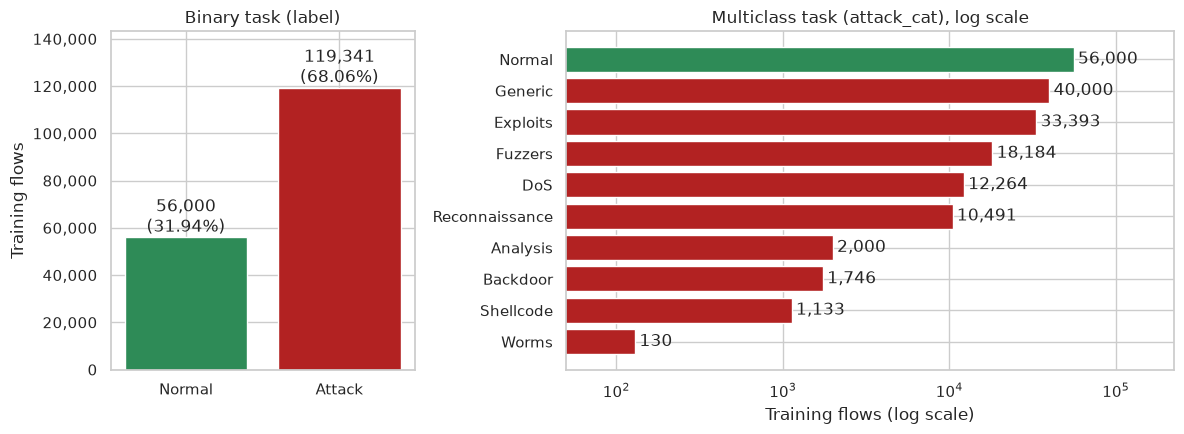

Guardada: artifacts/paper_figures/en/target_distribution.png
Guardada: artifacts/paper_figures/es/target_distribution.png


In [4]:
def draw_target_distribution(language):
    text = {
        "en": {"classes": ["Normal", "Attack"], "binary": "Binary task (label)", "flows": "Training flows",
               "multi": "Multiclass task (attack_cat), log scale", "flows_log": "Training flows (log scale)"},
        "es": {"classes": ["Normal", "Ataque"], "binary": "Tarea binaria (label)", "flows": "Flujos de entrenamiento",
               "multi": "Tarea multiclase (attack_cat), escala logarítmica", "flows_log": "Flujos de entrenamiento (escala log)"},
    }[language]
    fig, (ax_label, ax_cat) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 2]})

    label_counts = train[TARGET].value_counts().reindex([0, 1])  # orden fijo: normal, ataque
    label_share = (label_counts / len(train) * 100).round(2)
    bars = ax_label.bar(text["classes"], label_counts.to_numpy(), color=["seagreen", "firebrick"])
    ax_label.bar_label(bars, labels=[f"{number(n, 0, language)}\n({percent(p, 2, language)})" for n, p in zip(label_counts, label_share)])
    ax_label.set_ylim(0, label_counts.max() * 1.2)
    ax_label.set_title(text["binary"])
    ax_label.set_ylabel(text["flows"])
    ax_label.yaxis.set_major_formatter(axis_number(language, 0))

    cat_counts = train[ATTACK_CAT].value_counts().sort_values()
    colors = ["seagreen" if c == "Normal" else "firebrick" for c in cat_counts.index]
    bars = ax_cat.barh(cat_counts.index, cat_counts.to_numpy(), color=colors)
    ax_cat.bar_label(bars, labels=[number(n, 0, language) for n in cat_counts], padding=3)
    ax_cat.set_xscale("log")
    ax_cat.set_xlim(50, cat_counts.max() * 4)
    ax_cat.set_title(text["multi"])
    ax_cat.set_xlabel(text["flows_log"])

    fig.tight_layout()
    return fig


save_both(draw_target_distribution, "target_distribution", eda=True)

### `train_test_class_distribution`: proporción de cada clase en entrenamiento y prueba

El porcentaje de los flujos de cada `attack_cat` en las dos particiones, ordenado por el entrenamiento.

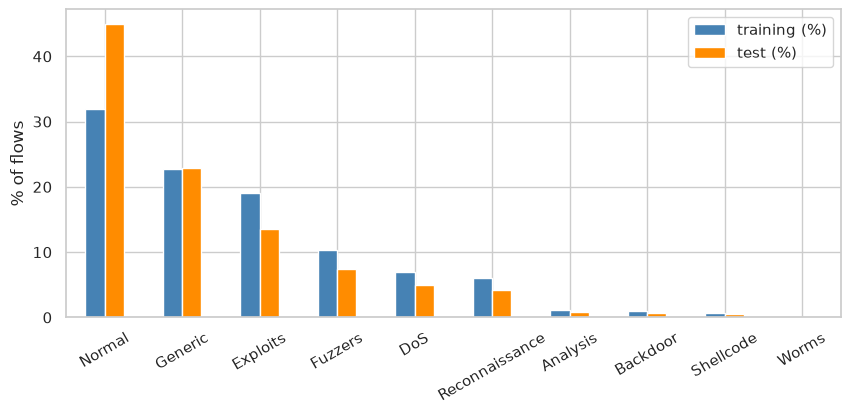

Guardada: artifacts/paper_figures/en/train_test_class_distribution.png
Guardada: artifacts/paper_figures/es/train_test_class_distribution.png


In [5]:
def draw_train_test_class_distribution(language):
    text = {
        "en": {"train": "training (%)", "test": "test (%)", "y": "% of flows"},
        "es": {"train": "entrenamiento (%)", "test": "prueba (%)", "y": "% de los flujos"},
    }[language]
    comparison = pd.DataFrame({
        text["train"]: train[ATTACK_CAT].value_counts(normalize=True) * 100,
        text["test"]: test[ATTACK_CAT].value_counts(normalize=True) * 100,
    }).round(2).sort_values(text["train"], ascending=False)
    fig, ax = plt.subplots(figsize=(10, 4))
    comparison.plot.bar(ax=ax, color=["steelblue", "darkorange"], rot=30)
    ax.set_xlabel("")
    ax.set_ylabel(text["y"])
    ax.yaxis.set_major_formatter(axis_number(language))
    return fig


save_both(draw_train_test_class_distribution, "train_test_class_distribution", eda=True)

### `repeated_flows_by_class`: flujos que repiten un patrón ya visto

Por clase, el porcentaje de flujos de entrenamiento idénticos (en las 42 variables) a uno anterior; al lado de cada barra, cuántos son.

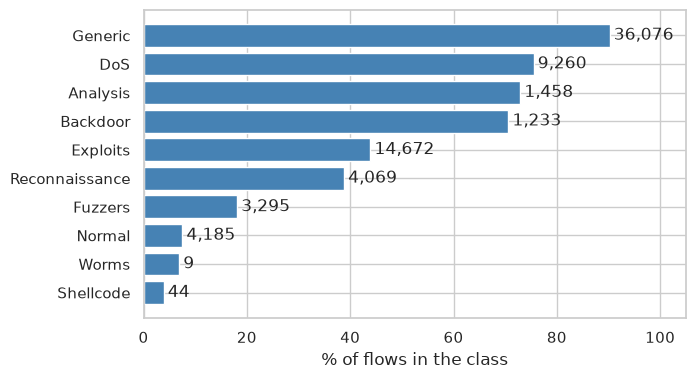

Guardada: artifacts/paper_figures/en/repeated_flows_by_class.png
Guardada: artifacts/paper_figures/es/repeated_flows_by_class.png


In [6]:
def draw_repeated_flows_by_class(language):
    text = {
        "en": {"title": "Flows that repeat an already seen pattern, by class", "x": "% of flows in the class"},
        "es": {"title": "Flujos que repiten un patrón ya visto, por clase", "x": "% de los flujos de la clase"},
    }[language]
    repeated = pattern_id.duplicated()
    by_class = pd.DataFrame({
        "flows": train[ATTACK_CAT].value_counts(),
        "repeated": train.loc[repeated, ATTACK_CAT].value_counts(),
    }).fillna(0).astype(int)
    by_class["repeated_pct"] = (by_class["repeated"] / by_class["flows"] * 100).round(1)
    by_class = by_class.sort_values("repeated_pct")

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.barh(by_class.index, by_class["repeated_pct"], color="steelblue")
    ax.bar_label(bars, labels=[number(n, 0, language) for n in by_class["repeated"]], padding=3)
    ax.set_xlabel(text["x"])
    ax.set_xlim(0, 105)
    return fig


save_both(draw_repeated_flows_by_class, "repeated_flows_by_class", eda=True)

### `ttl_by_class`: flujos por valor de TTL y clase

Para `sttl`, `dttl` y `ct_state_ttl`, los flujos de entrenamiento de cada valor con al menos 100 flujos, apilados por clase; los demás valores van juntos en «otros».

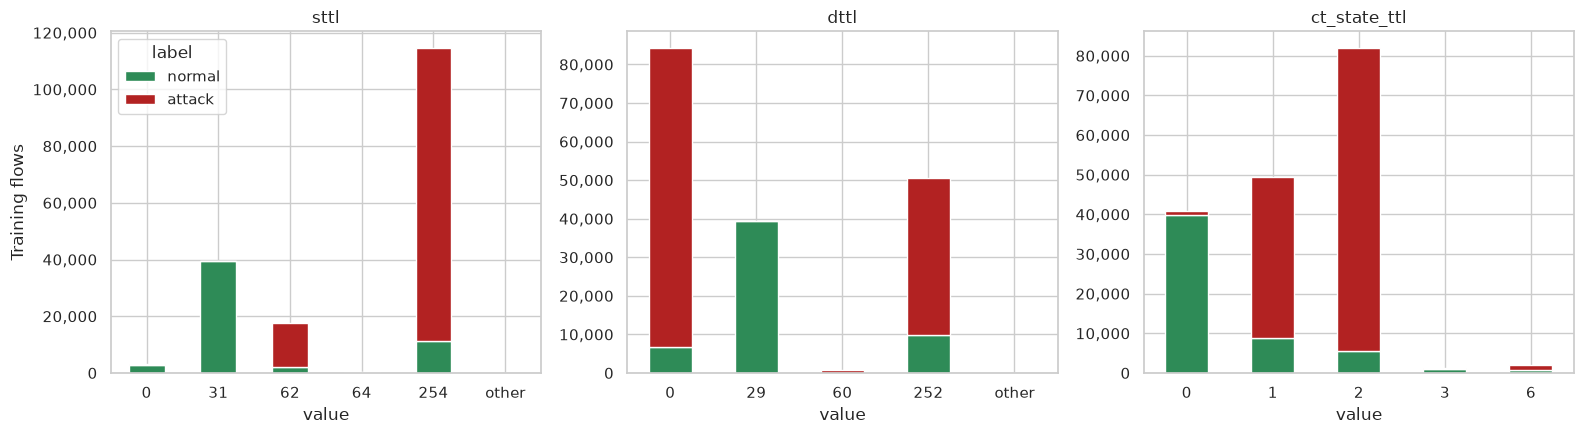

Guardada: artifacts/paper_figures/en/ttl_by_class.png
Guardada: artifacts/paper_figures/es/ttl_by_class.png


In [7]:
def draw_ttl_by_class(language):
    text = {
        "en": {"classes": {0: "normal", 1: "attack"}, "other": "other", "x": "value", "y": "Training flows"},
        "es": {"classes": {0: "normal", 1: "ataque"}, "other": "otros", "x": "valor", "y": "Flujos de entrenamiento"},
    }[language]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, col in zip(axes, ttl_cols):
        counts = train[col].value_counts()
        frequent = counts.index[counts >= 100]
        values = train[col].where(train[col].isin(frequent), other=-1)  # solo para visualizar
        table = pd.crosstab(values, train[TARGET]).rename(index={-1: text["other"]}, columns=text["classes"])
        table.index = table.index.astype(str)
        table = table.loc[[v for v in table.index if v != text["other"]] + [v for v in table.index if v == text["other"]]]
        table.plot.bar(stacked=True, color=["seagreen", "firebrick"], ax=ax, rot=0, legend=(col == ttl_cols[0]))
        ax.set_title(col)
        ax.set_xlabel(text["x"])
        ax.set_ylabel(text["y"] if col == ttl_cols[0] else "")
        ax.yaxis.set_major_formatter(axis_number(language, 0))
    fig.tight_layout()
    return fig


save_both(draw_ttl_by_class, "ttl_by_class", eda=True)

### `ttl_attack_rate_train_test`: proporción de ataques por valor de `sttl`

El porcentaje de ataques de cada valor de `sttl` con al menos 1.000 flujos de entrenamiento, en entrenamiento y en prueba.

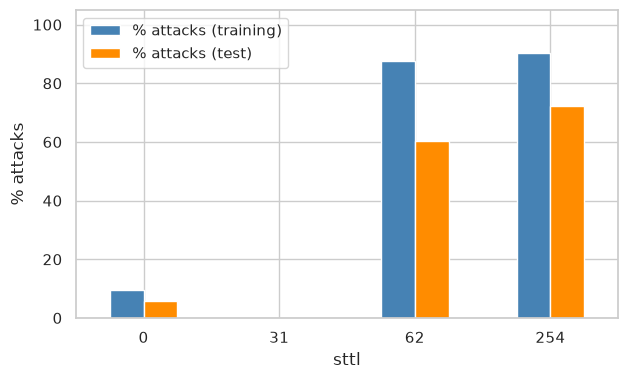

Guardada: artifacts/paper_figures/en/ttl_attack_rate_train_test.png
Guardada: artifacts/paper_figures/es/ttl_attack_rate_train_test.png


In [8]:
def draw_ttl_attack_rate_train_test(language):
    text = {
        "en": {"train": "% attacks (training)", "test": "% attacks (test)", "y": "% attacks"},
        "es": {"train": "% ataques (entrenamiento)", "test": "% ataques (prueba)", "y": "% de ataques"},
    }[language]
    comparison = pd.DataFrame({
        "train_flows": train["sttl"].value_counts(),
        text["train"]: train.groupby("sttl")[TARGET].mean() * 100,
        text["test"]: test.groupby("sttl")[TARGET].mean() * 100,
    }).loc[lambda d: d["train_flows"] >= 1000].round(1)
    fig, ax = plt.subplots(figsize=(7, 4))
    comparison[[text["train"], text["test"]]].plot.bar(ax=ax, color=["steelblue", "darkorange"], rot=0)
    ax.set_xlabel("sttl")
    ax.set_ylabel(text["y"])
    ax.set_ylim(0, 105)
    return fig


save_both(draw_ttl_attack_rate_train_test, "ttl_attack_rate_train_test", eda=True)

### `train_test_shift`: cambio de distribución entre entrenamiento y prueba

La distancia de Kolmogorov–Smirnov entre entrenamiento y prueba de las variables numéricas que se conservan, solo entre normales y solo entre ataques; las 12 con más cambio entre los normales. La línea punteada marca 0,2. Se calcula con la misma función del notebook 01.

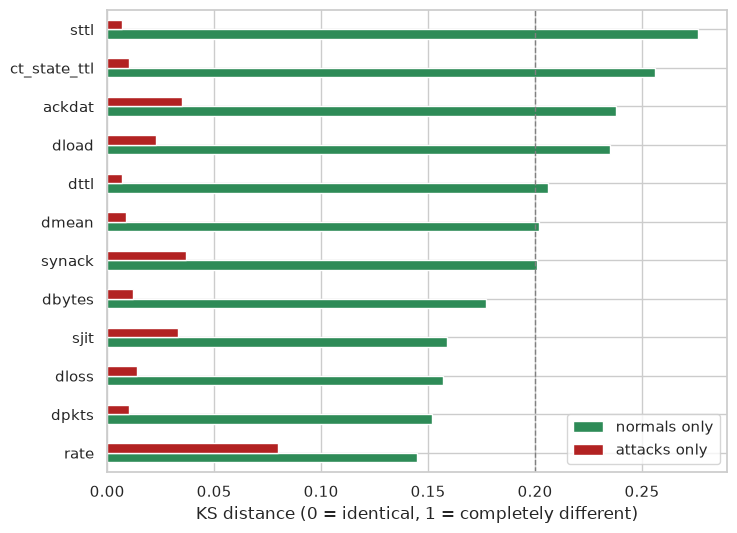

Guardada: artifacts/paper_figures/en/train_test_shift.png
Guardada: artifacts/paper_figures/es/train_test_shift.png


In [9]:
def ks_distance(a, b):
    """Mayor diferencia entre las distribuciones acumuladas de dos muestras (la del notebook 01)."""
    a, b = np.sort(a), np.sort(b)
    values = np.union1d(a, b)
    cdf_a = np.searchsorted(a, values, side="right") / len(a)
    cdf_b = np.searchsorted(b, values, side="right") / len(b)
    return np.abs(cdf_a - cdf_b).max()


dropped_so_far = ["is_ftp_login", "stcpb", "dtcpb", "swin", "dwin", "tcprtt", "is_sm_ips_ports"]
kept_numeric = [c for c in numeric_cols if c not in dropped_so_far]
shift = pd.DataFrame({
    "normals": {c: ks_distance(train.loc[train[TARGET] == 0, c], test.loc[test[TARGET] == 0, c]) for c in kept_numeric},
    "attacks": {c: ks_distance(train.loc[train[TARGET] == 1, c], test.loc[test[TARGET] == 1, c]) for c in kept_numeric},
}).round(3).sort_values("normals", ascending=False)


def draw_train_test_shift(language):
    text = {
        "en": {"normals": "normals only", "attacks": "attacks only",
               "x": "KS distance (0 = identical, 1 = completely different)"},
        "es": {"normals": "solo normales", "attacks": "solo ataques",
               "x": "Distancia KS (0 = igual, 1 = totalmente distinta)"},
    }[language]
    top_shift = shift.head(12).rename(columns={"normals": text["normals"], "attacks": text["attacks"]}).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 6))
    top_shift.plot.barh(ax=ax, color=["seagreen", "firebrick"])
    ax.axvline(0.2, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel(text["x"])
    ax.xaxis.set_major_formatter(axis_number(language, 2))
    return fig


save_both(draw_train_test_shift, "train_test_shift", eda=True)

## 5. Búsqueda de modelos en validación

### `defaults_scores`: barrido con valores por defecto

Desde `search_results.csv` (fase 1), como en el notebook 05: la PR-AUC del detector y el F1 macro del clasificador de tipos de cada familia (sin dummy) con cada método de preprocesamiento. Un marcador sin relleno indica que el detector o el clasificador no convergió.

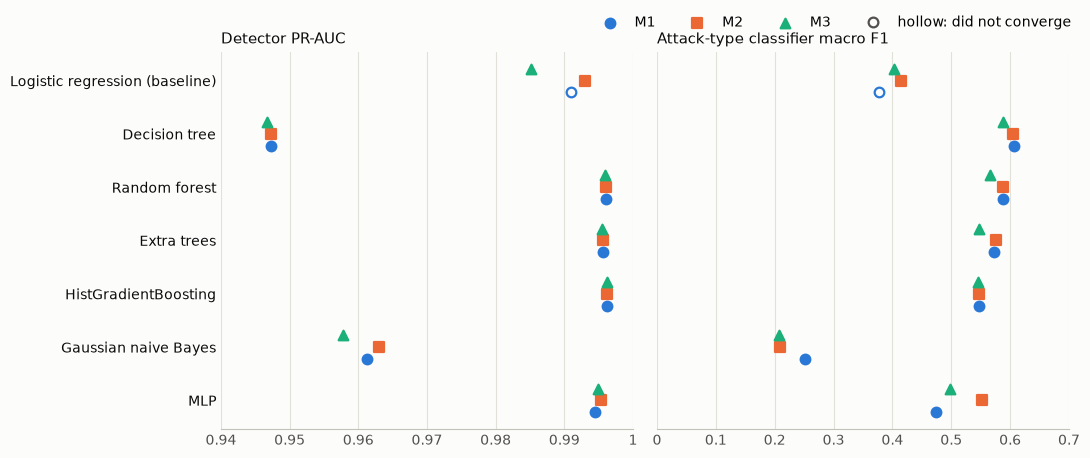

Guardada: artifacts/paper_figures/en/defaults_scores.png
Guardada: artifacts/paper_figures/es/defaults_scores.png


In [10]:
defaults = search[search["phase"] == 1]
detectors = defaults[defaults["task"] == "detector"].set_index(["family", "requested_method"])
classifiers = defaults[defaults["task"] == "attack_type"].set_index(["family", "requested_method"])
defaults_summary = pd.DataFrame({
    "pr_auc": detectors["pr_auc"],
    "f1_macro": classifiers["macro_f1"],
    "converged": detectors["converged"] & classifiers["converged"],
})
METHOD_STYLES = {  # paleta categórica validada (3 colores) y una forma por método
    "m1": {"color": "#2a78d6", "marker": "o"},
    "m2": {"color": "#eb6834", "marker": "s"},
    "m3": {"color": "#1baf7a", "marker": "^"},
}


def draw_defaults_scores(language):
    text = {
        "en": {"pr_auc": "Detector PR-AUC", "f1": "Attack-type classifier macro F1", "hollow": "hollow: did not converge"},
        "es": {"pr_auc": "PR-AUC del detector", "f1": "F1 macro del clasificador de tipos", "hollow": "sin relleno: no convergió"},
    }[language]
    plotted = [family for family in MODEL_FAMILIES if family != "dummy"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, facecolor=SURFACE)
    panels = [("pr_auc", text["pr_auc"], (0.94, 1.0)), ("f1_macro", text["f1"], (0.0, 0.7))]
    for ax, (column, title, limits) in zip(axes, panels):
        ax.set_facecolor(SURFACE)
        for offset, (method, style) in zip((-0.22, 0, 0.22), METHOD_STYLES.items()):
            for position, family in enumerate(reversed(plotted)):
                row = defaults_summary.loc[(family, method)]
                ax.scatter(row[column], position + offset, s=48, marker=style["marker"], color=style["color"],
                           facecolor=style["color"] if row["converged"] else SURFACE, linewidth=1.6, zorder=3,
                           label=method.upper() if position == 0 else None)
        ax.set_xlim(*limits)
        ax.set_title(title, color=INK, fontsize=11, loc="left")
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
        ax.xaxis.set_major_formatter(axis_number(language))
    axes[0].set_yticks(range(len(plotted)), [MODEL_NAMES[language][f] for f in reversed(plotted)], color=INK)
    handles, labels = axes[1].get_legend_handles_labels()
    hollow = Line2D([], [], marker="o", linestyle="", markersize=7, color=MUTED, markerfacecolor=SURFACE, markeredgewidth=1.6)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.legend([*handles, hollow], [*labels, text["hollow"]], ncol=4, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    return fig


save_both(draw_defaults_scores, "defaults_scores")

### `train_validation_gap`: brecha entre validación y entrenamiento

Desde `train_validation_gap.csv`, como en el notebook 05: la diferencia entre validación y entrenamiento en la PR-AUC del detector y en el F1 macro de tipos, para los modelos que se registran (azul) y para casos de la búsqueda que sobreentrenan (gris). En inglés se traducen los nombres de los casos, que en el archivo están en español.

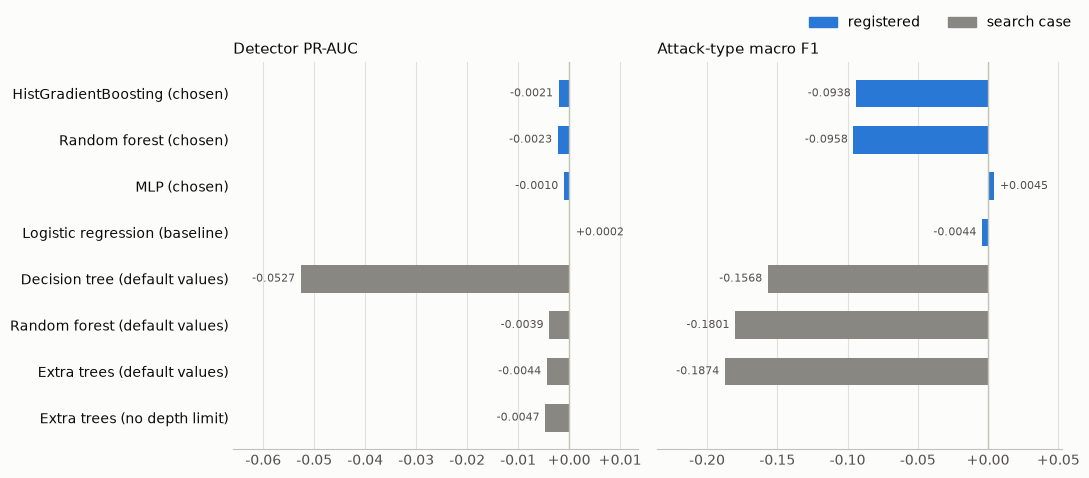

Guardada: artifacts/paper_figures/en/train_validation_gap.png
Guardada: artifacts/paper_figures/es/train_validation_gap.png


In [11]:
# En el archivo, cada caso es "<familia> (elegido)", "<familia> (modelo base)", "<familia> por defecto" o
# "<familia> sin límite de profundidad". En la figura: el nombre del artículo y el caso entre paréntesis.
CASES = {
    "en": {"(elegido)": " (chosen)", "(modelo base)": "", "por defecto": " (default values)",
           "sin límite de profundidad": " (no depth limit)"},
    "es": {"(elegido)": " (elegido)", "(modelo base)": "", "por defecto": " (valores por defecto)",
           "sin límite de profundidad": " (sin límite de profundidad)"},
}


def case_name(name, language):
    family, case = name.split(" ", 1)
    return MODEL_NAMES[language][family] + CASES[language][case]


def draw_train_validation_gap(language):
    text = {
        "en": {"pr_auc": "Detector PR-AUC", "f1": "Attack-type macro F1", "registered": "registered",
               "search": "search case"},
        "es": {"pr_auc": "PR-AUC del detector", "f1": "F1 macro de tipos", "registered": "se registra",
               "search": "caso de la búsqueda"},
    }[language]
    registered_color, search_color = "#2a78d6", "#898781"
    names = list(dict.fromkeys(gap["modelo"]))  # en el orden del archivo
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True, facecolor=SURFACE)
    for ax, (metric, title) in zip(axes, [("PR-AUC", text["pr_auc"]), ("F1 macro", text["f1"])]):
        ax.set_facecolor(SURFACE)
        subset = gap[gap["métrica"] == metric].set_index("modelo")
        for position, name in enumerate(reversed(names)):
            if name not in subset.index:
                continue
            value = subset.loc[name, "brecha"]
            color = search_color if subset.loc[name, "caso"] == "sobreentrenado" else registered_color
            ax.barh(position, value, color=color, height=0.6)
            ax.annotate(signed(value, 4, language), (value, position), xytext=(-4 if value < 0 else 4, 0),
                        textcoords="offset points", ha="right" if value < 0 else "left", va="center", color=MUTED, fontsize=8)
        ax.axvline(0, color=AXIS, linewidth=1)
        ax.set_title(title, loc="left", color=INK, fontsize=11)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: signed(value, 2, language)))
        ax.margins(x=0.25)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
    axes[0].set_yticks(range(len(names)), [case_name(n, language) for n in reversed(names)], color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.legend([Patch(color=registered_color), Patch(color=search_color)], [text["registered"], text["search"]],
               ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    return fig


save_both(draw_train_validation_gap, "train_validation_gap")

## 6. Resultados en prueba

### `validation_vs_test` y `ttl_test`

Desde `test_results.csv`, con la misma función de barras de pesas del notebook 06: para cada fila, el valor de la izquierda (gris) y el de la derecha (azul).

- `validation_vs_test`: recall y falsas alarmas del detector y F1 macro de tipos, en validación y en prueba, de las 8 familias.
- `ttl_test`: el experimento de TTL en prueba: los 3 modelos elegidos con TTL (M1 o M2, el método de cada modelo) y sin TTL (M3, mismos hiperparámetros).

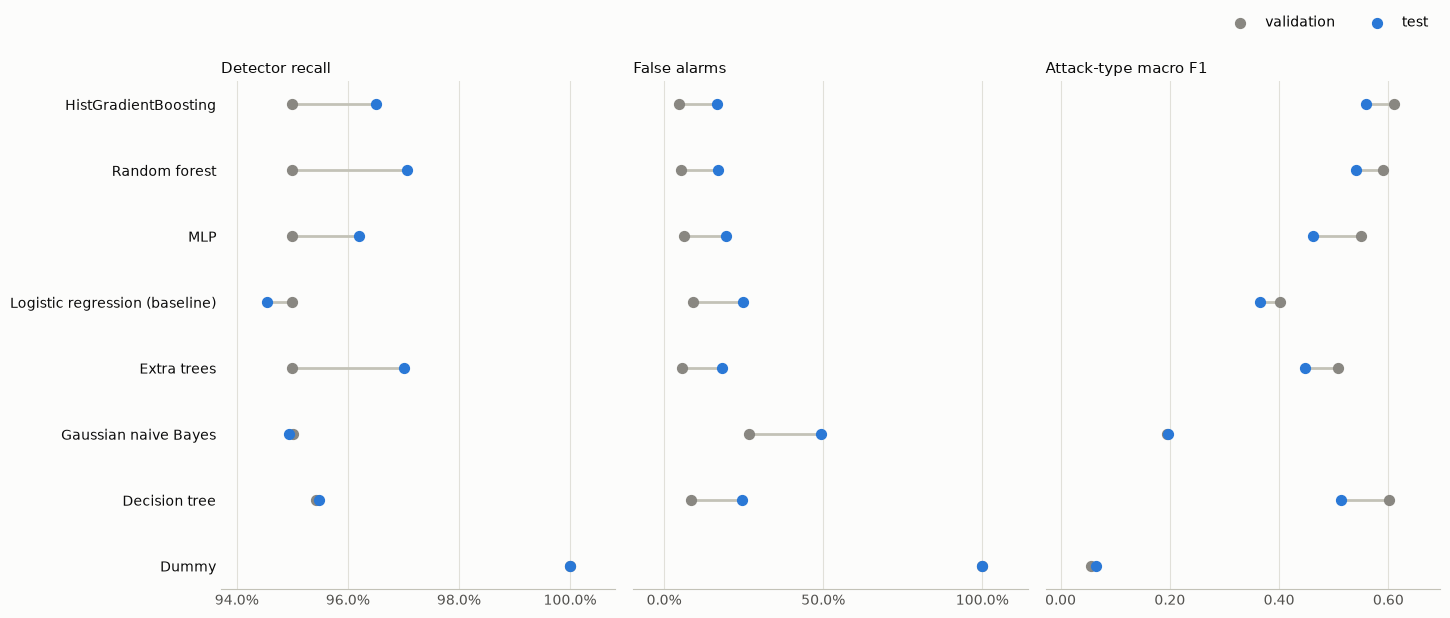

Guardada: artifacts/paper_figures/en/validation_vs_test.png
Guardada: artifacts/paper_figures/es/validation_vs_test.png


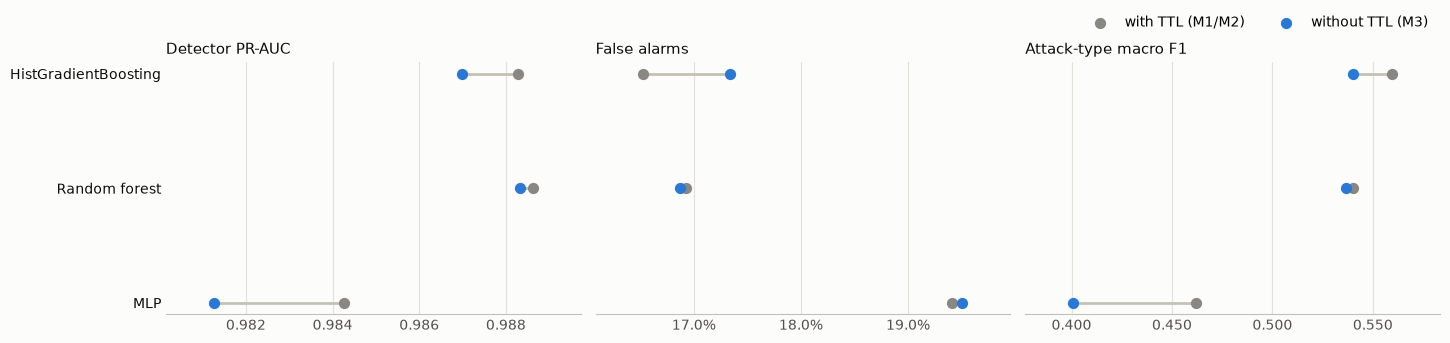

Guardada: artifacts/paper_figures/en/ttl_test.png
Guardada: artifacts/paper_figures/es/ttl_test.png


In [12]:
VALIDATION_COLOR, TEST_COLOR = "#898781", "#2a78d6"


def draw_dumbbells(rows, panels, left, right, labels, language):
    """Un panel por métrica; cada fila une el valor de left (gris) con el de right (azul)."""
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels) + 2, 0.55 * len(rows) + 1.8), sharey=True, facecolor=SURFACE)
    for ax, (metric, panel_title, formatter) in zip(axes, panels):
        ax.set_facecolor(SURFACE)
        for position, (_, row) in enumerate(reversed(list(rows.iterrows()))):
            a, b = row[left.format(metric)], row[right.format(metric)]
            ax.plot([a, b], [position, position], color=AXIS, linewidth=2, zorder=1)
            ax.scatter(a, position, s=50, color=VALIDATION_COLOR, zorder=2, label=labels[0] if position == 0 else None)
            ax.scatter(b, position, s=50, color=TEST_COLOR, zorder=3, label=labels[1] if position == 0 else None)
        ax.set_title(panel_title, loc="left", color=INK, fontsize=11)
        ax.xaxis.set_major_formatter(formatter)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        ax.margins(x=0.15)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
    axes[0].set_yticks(range(len(rows)), [MODEL_NAMES[language][name] for name in reversed(rows.index)], color=INK)
    handles, names = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.legend(handles, names, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    return fig


families = results[results["kind"] != "m3"].set_index("name")
chosen = results[results["kind"] == "elegido"].set_index("family")
m3 = results[results["kind"] == "m3"].set_index("family")
ttl = pd.DataFrame({
    f"{metric}_{version}": table.loc[chosen.index, f"test_{metric}"]
    for metric in ("pr_auc", "false_alarm_rate", "macro_f1")
    for version, table in (("app", chosen), ("m3", m3))
})


def draw_validation_vs_test(language):
    text = {
        "en": {"recall": "Detector recall", "fa": "False alarms", "f1": "Attack-type macro F1", "labels": ("validation", "test")},
        "es": {"recall": "Recall del detector", "fa": "Falsas alarmas", "f1": "F1 macro de tipos", "labels": ("validación", "prueba")},
    }[language]
    panels = [("recall", text["recall"], axis_percent(language, 1)), ("false_alarm_rate", text["fa"], axis_percent(language, 1)),
              ("macro_f1", text["f1"], axis_number(language, 2))]
    return draw_dumbbells(families, panels, "validation_{}", "test_{}", text["labels"], language)


def draw_ttl_test(language):
    text = {
        "en": {"pr_auc": "Detector PR-AUC", "fa": "False alarms", "f1": "Attack-type macro F1",
               "labels": ("with TTL (M1/M2)", "without TTL (M3)")},
        "es": {"pr_auc": "PR-AUC del detector", "fa": "Falsas alarmas", "f1": "F1 macro de tipos",
               "labels": ("con TTL (M1/M2)", "sin TTL (M3)")},
    }[language]
    panels = [("pr_auc", text["pr_auc"], axis_number(language, 3)), ("false_alarm_rate", text["fa"], axis_percent(language, 1)),
              ("macro_f1", text["f1"], axis_number(language, 3))]
    return draw_dumbbells(ttl, panels, "{}_app", "{}_m3", text["labels"], language)


save_both(draw_validation_vs_test, "validation_vs_test")
save_both(draw_ttl_test, "ttl_test")

### `test_f1_per_type`: F1 por tipo de ataque en prueba

Desde `test_per_type.csv`: el F1 de cada tipo de ataque en prueba para las 8 familias, con el mismo mapa de color del notebook 06. «—» indica un F1 que no se puede calcular.

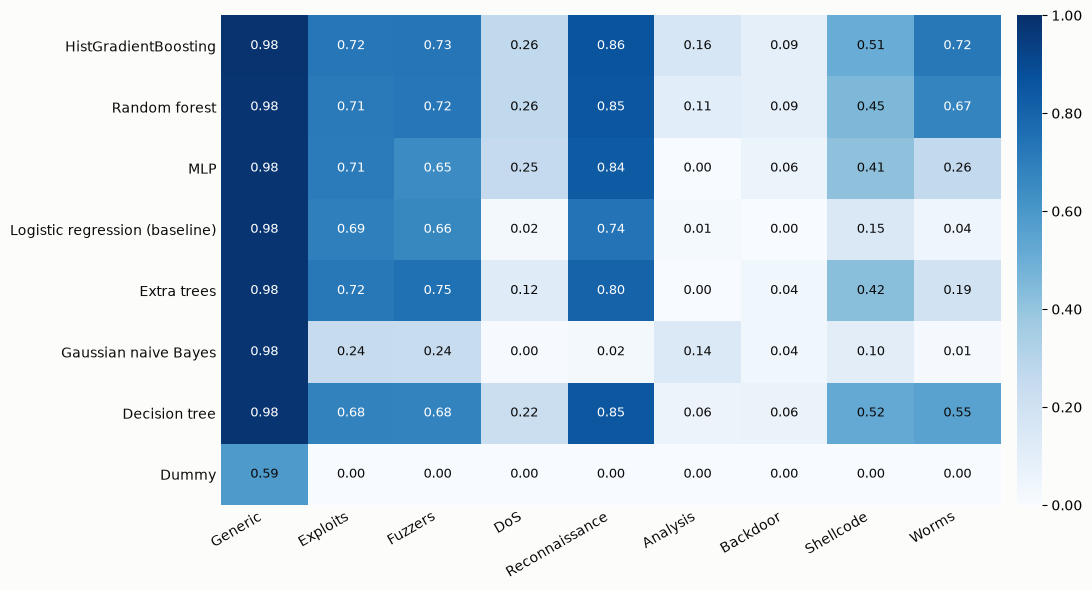

Guardada: artifacts/paper_figures/en/test_f1_per_type.png
Guardada: artifacts/paper_figures/es/test_f1_per_type.png


In [13]:
def draw_test_f1_per_type(language):
    title = {"en": "F1 per attack type on test", "es": "F1 por tipo de ataque en prueba"}[language]
    test_types = per_type[per_type["split"] == "test"]
    f1_table = test_types.pivot(index="name", columns="attack_cat", values="f1").reindex(index=families.index, columns=ATTACK_TYPES)
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(f1_table) + 1.6), facecolor=SURFACE)
    image = ax.imshow(f1_table.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(f1_table.shape[0]):
        for j in range(f1_table.shape[1]):
            value = f1_table.iat[i, j]
            label = "—" if pd.isna(value) else number(value, 2, language)
            ax.text(j, i, label, ha="center", va="center", fontsize=9, color="white" if not pd.isna(value) and value > 0.6 else INK)
    ax.set_xticks(range(len(ATTACK_TYPES)), ATTACK_TYPES, rotation=30, ha="right", color=INK)
    ax.set_yticks(range(len(f1_table)), [MODEL_NAMES[language][name] for name in f1_table.index], color=INK)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    colorbar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
    colorbar.ax.yaxis.set_major_formatter(axis_number(language, 2))
    colorbar.outline.set_visible(False)
    fig.tight_layout()
    return fig


save_both(draw_test_f1_per_type, "test_f1_per_type")

### `test_confusion_hgb`: matrices de confusión de HistGradientBoosting en prueba

Desde `test_results.csv`, como en la sección 8 del notebook 06: la 2×2 del detector con el conteo y el porcentaje de cada clase real, y la 9×9 de tipos de ataque, medida solo sobre los ataques reales que dieron alerta, con el color según el porcentaje de cada fila.

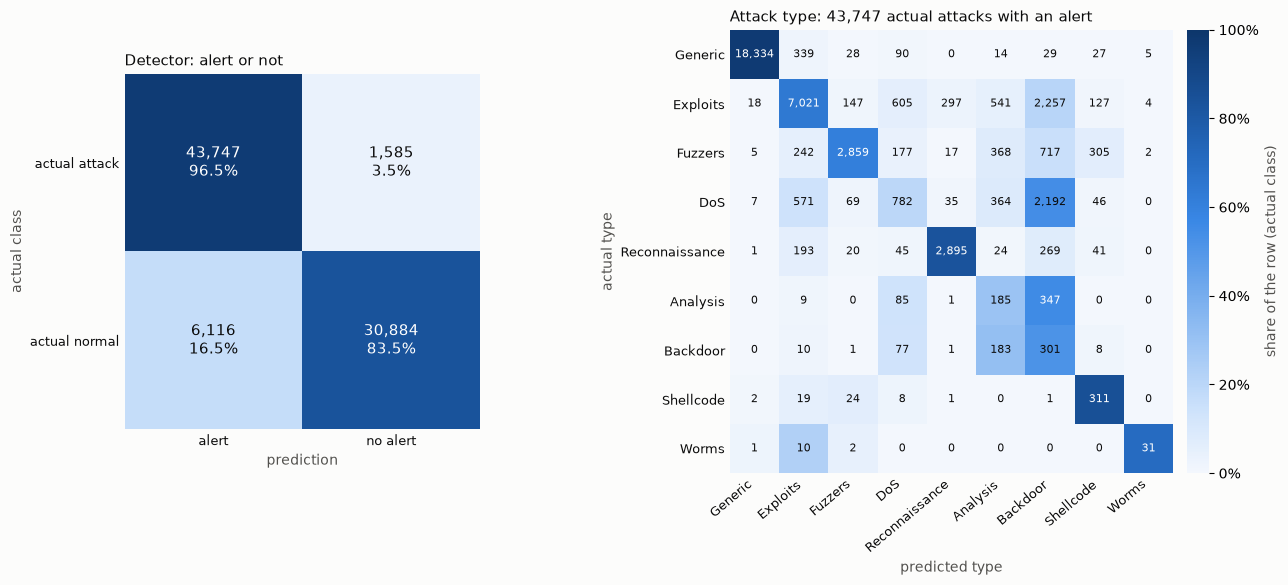

Guardada: artifacts/paper_figures/en/test_confusion_hgb.png
Guardada: artifacts/paper_figures/es/test_confusion_hgb.png


In [14]:
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "azul", ["#f3f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
DARK_CELL = 0.55  # desde esta fracción, el texto de la celda va en blanco
hgb_row = results.set_index("name").loc["hist_gradient_boosting"]
type_confusion = json.loads(hgb_row["test_metrics_json"])["attack_type"]["confusion"]
type_matrix = pd.DataFrame(type_confusion["matrix"], index=type_confusion["labels"], columns=type_confusion["labels"])
type_share = type_matrix.div(type_matrix.sum(axis=1), axis=0)
detection_counts = np.array([[hgb_row["test_tp"], hgb_row["test_fn"]], [hgb_row["test_fp"], hgb_row["test_tn"]]])


def matrix_panel(ax, shares, counts, title, xlabel, ylabel, fontsize, language):
    ax.imshow(shares.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1)
    for i in range(shares.shape[0]):
        for j in range(shares.shape[1]):
            share, count = shares.iat[i, j], counts.iat[i, j]
            # En la 2×2 van el conteo y el porcentaje de la fila; en la 9×9, solo el conteo (el color es el porcentaje).
            label = number(count, 0, language) + (f"\n{percent(share * 100, 1, language)}" if fontsize > 8 else "")
            ax.text(j, i, label, ha="center", va="center", fontsize=fontsize, color="white" if share >= DARK_CELL else INK)
    ax.set_xticks(range(shares.shape[1]), shares.columns, rotation=40 if shares.shape[1] > 2 else 0,
                  ha="right" if shares.shape[1] > 2 else "center", color=INK, fontsize=9)
    ax.set_yticks(range(shares.shape[0]), shares.index, color=INK, fontsize=9)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)


def draw_test_confusion_hgb(language):
    text = {
        "en": {"rows": ["actual attack", "actual normal"], "columns": ["alert", "no alert"], "detector": "Detector: alert or not",
               "prediction": "prediction", "actual": "actual class", "types": "Attack type: {} actual attacks with an alert",
               "predicted_type": "predicted type", "actual_type": "actual type", "bar": "share of the row (actual class)"},
        "es": {"rows": ["ataque real", "normal real"], "columns": ["alerta", "sin alerta"], "detector": "Detector: alerta o no",
               "prediction": "predicción", "actual": "clase real", "types": "Tipo de ataque: {} ataques reales con alerta",
               "predicted_type": "tipo predicho", "actual_type": "tipo real", "bar": "parte de la fila (clase real)"},
    }[language]
    detection = pd.DataFrame(detection_counts, index=text["rows"], columns=text["columns"])
    detection_share = detection.div(detection.sum(axis=1), axis=0)
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.9]}, facecolor=SURFACE)
    matrix_panel(left, detection_share, detection, text["detector"], text["prediction"], text["actual"], 11, language)
    matrix_panel(right, type_share, type_matrix, text["types"].format(number(type_matrix.values.sum(), 0, language)),
                 text["predicted_type"], text["actual_type"], 8, language)
    colorbar = fig.colorbar(plt.cm.ScalarMappable(cmap=SEQUENTIAL, norm=plt.Normalize(0, 1)), ax=right, fraction=0.035, pad=0.02)
    colorbar.ax.yaxis.set_major_formatter(axis_percent(language, 0))
    colorbar.set_label(text["bar"], color=MUTED)
    colorbar.outline.set_visible(False)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


save_both(draw_test_confusion_hgb, "test_confusion_hgb")

### `test_pr_curves`: curvas precisión-recall en prueba

Como en la sección 8 del notebook 06. Los 4 modelos registrados predicen la prueba con `predict_flows` (las mismas predicciones de la evaluación); la curva sale de `precision_recall_curve`. La PR-AUC de la leyenda y los puntos de operación son los guardados en `test_results.csv`. Como comprobación, la PR-AUC de cada curva debe coincidir con la guardada con una tolerancia de 1e-6, por el ruido de Random Forest con `n_jobs=-1` y sus empates de probabilidad (explicado en el notebook 06 y en `artifacts/model_search/README.md`). Las predicciones se hacen una sola vez y sirven para los dos idiomas.

hist_gradient_boosting: diferencia con la PR-AUC guardada 0.0e+00
random_forest: diferencia con la PR-AUC guardada 1.5e-10
mlp: diferencia con la PR-AUC guardada 1.1e-16
logistic_regression: diferencia con la PR-AUC guardada 0.0e+00


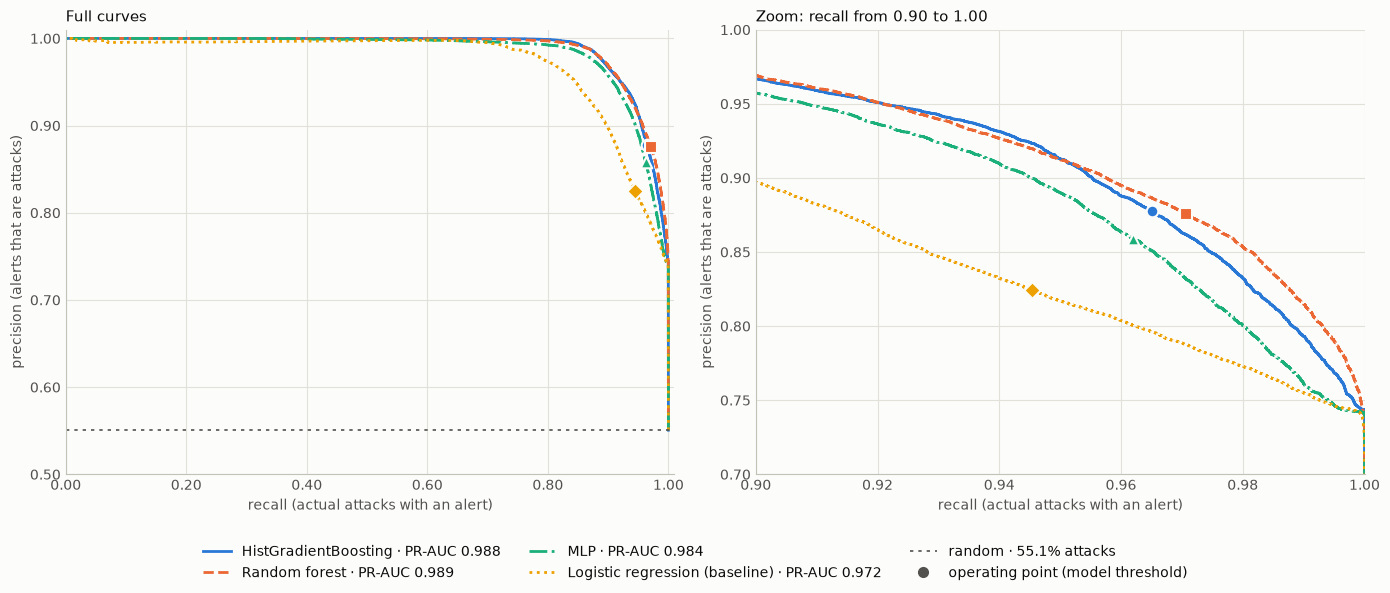

Guardada: artifacts/paper_figures/en/test_pr_curves.png
Guardada: artifacts/paper_figures/es/test_pr_curves.png


In [15]:
PR_AUC_TOLERANCE = 1e-6  # ruido de Random Forest con n_jobs=-1 y empates de probabilidad
PR_STYLES = {
    "hist_gradient_boosting": ("#2a78d6", "-", "o"),
    "random_forest": ("#eb6834", "--", "s"),
    "mlp": ("#1baf7a", "-.", "^"),
    "logistic_regression": ("#eda100", ":", "D"),
}
y_test = test[TARGET].to_numpy()
saved = results.set_index("name")
curves = {}
for name in PR_STYLES:
    info = read_model_info(name)
    probability, _, _ = predict_flows(load_model(name, info), info, test)
    difference = abs(average_precision_score(y_test, probability) - saved.loc[name, "test_pr_auc"])
    assert difference <= PR_AUC_TOLERANCE, f"{name}: la PR-AUC difiere {difference:.1e} de la guardada"
    precision, recall, _ = precision_recall_curve(y_test, probability)
    curves[name] = (recall, precision)
    print(f"{name}: diferencia con la PR-AUC guardada {difference:.1e}")
attack_share = y_test.mean()


def draw_test_pr_curves(language):
    text = {
        "en": {"random": "random · {} attacks", "point": "operating point (model threshold)", "zoom": "Zoom: recall from {} to {}",
               "full": "Full curves", "x": "recall (actual attacks with an alert)", "y": "precision (alerts that are attacks)"},
        "es": {"random": "al azar · {} de ataques", "point": "punto de operación (umbral del modelo)", "zoom": "Acercamiento: recall de {} a {}",
               "full": "Curvas completas", "x": "recall (ataques reales con alerta)", "y": "precisión (alertas que son ataques)"},
    }[language]
    zoom = {"recall": (0.90, 1.00), "precision": (0.70, 1.00)}
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), facecolor=SURFACE)
    for ax, zoomed in zip(axes, (False, True)):
        ax.set_facecolor(SURFACE)
        for name, (color, line, marker) in PR_STYLES.items():
            recall, precision = curves[name]
            ax.plot(recall, precision, color=color, linestyle=line, linewidth=2,
                    label=f"{MODEL_NAMES[language][name]} · PR-AUC {number(saved.loc[name, 'test_pr_auc'], 3, language)}")
            ax.scatter(saved.loc[name, "test_recall"], saved.loc[name, "test_precision"], s=70, marker=marker,
                       color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ax.axhline(attack_share, color=MUTED, linestyle=(0, (2, 3)), linewidth=1.2,
                   label=text["random"].format(percent(attack_share * 100, 1, language)))
        if zoomed:
            ax.set_xlim(*zoom["recall"])
            ax.set_ylim(*zoom["precision"])
            ax.set_title(text["zoom"].format(*(number(v, 2, language) for v in zoom["recall"])), loc="left", color=INK, fontsize=11)
        else:
            ax.set_xlim(0, 1.01)
            ax.set_ylim(0.5, 1.01)
            ax.set_title(text["full"], loc="left", color=INK, fontsize=11)
        ax.xaxis.set_major_formatter(axis_number(language, 2))
        ax.yaxis.set_major_formatter(axis_number(language, 2))
        ax.set_xlabel(text["x"], color=MUTED)
        ax.set_ylabel(text["y"], color=MUTED)
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
    handles, labels = axes[0].get_legend_handles_labels()
    point = plt.Line2D([], [], color=MUTED, marker="o", linestyle="none", markersize=7, label=text["point"])
    fig.legend([*handles, point], [*labels, point.get_label()], loc="lower center", ncol=3, frameon=False, labelcolor=INK)
    fig.tight_layout(rect=(0, 0.1, 1, 0.96))
    return fig


save_both(draw_test_pr_curves, "test_pr_curves")

## 7. Interpretación y falsas alarmas

### `global_importance`: importancia global de las variables

Desde `global_importance.csv` (primera muestra), como en la sección 7 del notebook 06: las 15 variables con mayor participación en la importancia total de cada detector; las de TTL en naranja y `proto` en verde.

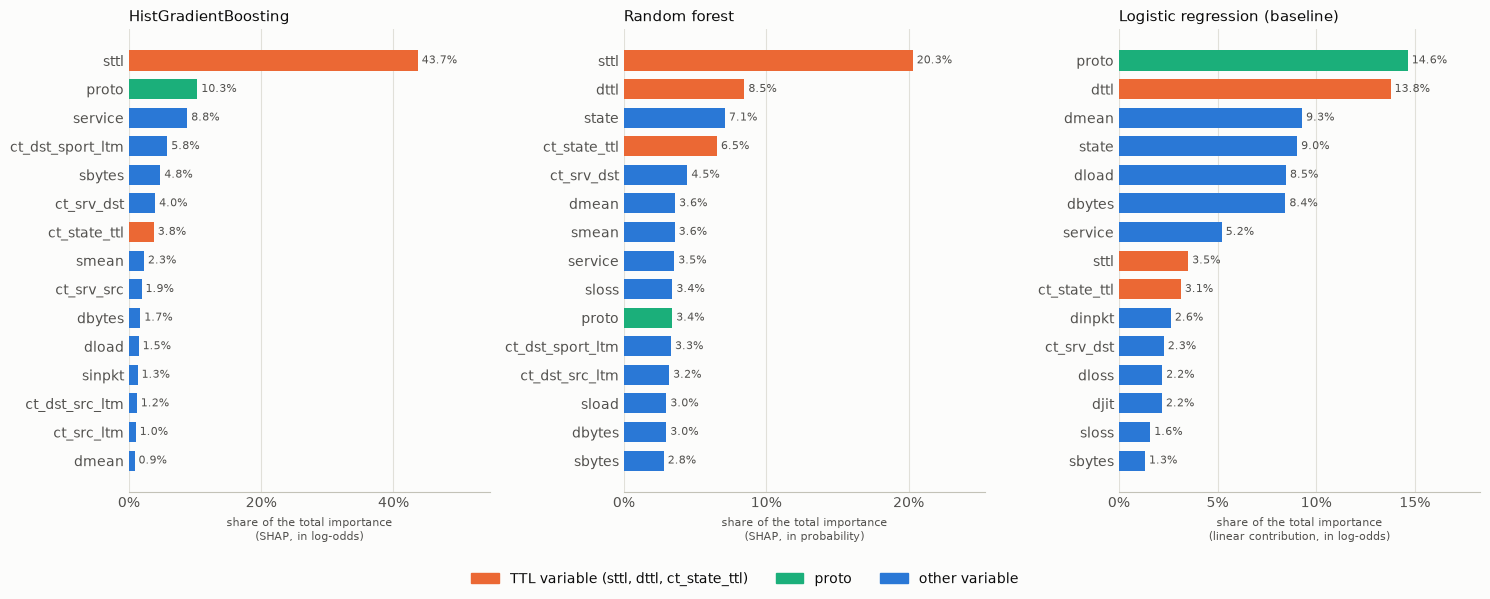

Guardada: artifacts/paper_figures/en/global_importance.png
Guardada: artifacts/paper_figures/es/global_importance.png


In [16]:
IMPORTANCE_MODELS = {"hist_gradient_boosting": ("SHAP", "log-odds"), "random_forest": ("SHAP", "probability"),
                     "logistic_regression": ("linear", "log-odds")}
TTL_VARIABLES = ["sttl", "dttl", "ct_state_ttl"]
BAR_COLORS = {"ttl": "#eb6834", "proto": "#1baf7a", "other": "#2a78d6"}
first_sample = importance[importance["sample"] == 1]


def draw_global_importance(language):
    text = {
        "en": {"methods": {"SHAP": "SHAP", "linear": "linear contribution"}, "scales": {"log-odds": "log-odds", "probability": "probability"},
               "x": "share of the total importance\n({}, in {})",
               "legend": ["TTL variable (sttl, dttl, ct_state_ttl)", "proto", "other variable"]},
        "es": {"methods": {"SHAP": "SHAP", "linear": "contribución lineal"}, "scales": {"log-odds": "log-odds", "probability": "probabilidad"},
               "x": "participación en la importancia total\n({}, en {})",
               "legend": ["variable de TTL (sttl, dttl, ct_state_ttl)", "proto", "otra variable"]},
    }[language]
    kind_of = lambda feature: "ttl" if feature in TTL_VARIABLES else ("proto" if feature == "proto" else "other")
    fig, axes = plt.subplots(1, len(IMPORTANCE_MODELS), figsize=(15, 6.2), facecolor=SURFACE)
    for ax, (name, (method, scale)) in zip(axes, IMPORTANCE_MODELS.items()):
        rows = first_sample[first_sample["model"] == name].head(15).iloc[::-1]
        ax.set_facecolor(SURFACE)
        ax.barh(range(len(rows)), rows["share"], height=0.7, color=[BAR_COLORS[kind_of(f)] for f in rows["feature"]])
        for position, share in enumerate(rows["share"]):
            ax.text(share, position, " " + percent(share * 100, 1, language), va="center", color=MUTED, fontsize=8)
        ax.set_yticks(range(len(rows)), rows["feature"], color=INK)
        ax.xaxis.set_major_formatter(axis_percent(language, 0))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        ax.set_xlim(0, rows["share"].max() * 1.25)
        ax.set_xlabel(text["x"].format(text["methods"][method], text["scales"][scale]), color=MUTED, fontsize=8)
        ax.set_title(MODEL_NAMES[language][name], loc="left", color=INK, fontsize=11)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
    handles = [plt.Rectangle((0, 0), 1, 1, color=BAR_COLORS[k]) for k in BAR_COLORS]
    fig.legend(handles, text["legend"], loc="lower center", ncol=3, frameon=False, labelcolor=INK)
    fig.tight_layout(rect=(0, 0.06, 1, 0.97))
    return fig


save_both(draw_global_importance, "global_importance")

### `false_alarms_by_category`: tasa de falsas alarmas por categoría

Desde `false_alarms_by_category.csv`, como en la sección 5 del notebook 06: para HistGradientBoosting y cada variable categórica, las 8 categorías con más falsas alarmas en prueba, con su tasa en entrenamiento, validación y prueba. Junto a cada categoría: cómo la ve el modelo (propia, agrupada o nueva) y cuántos normales tiene en cada parte. Un marcador sin relleno indica menos de 100 normales en prueba.

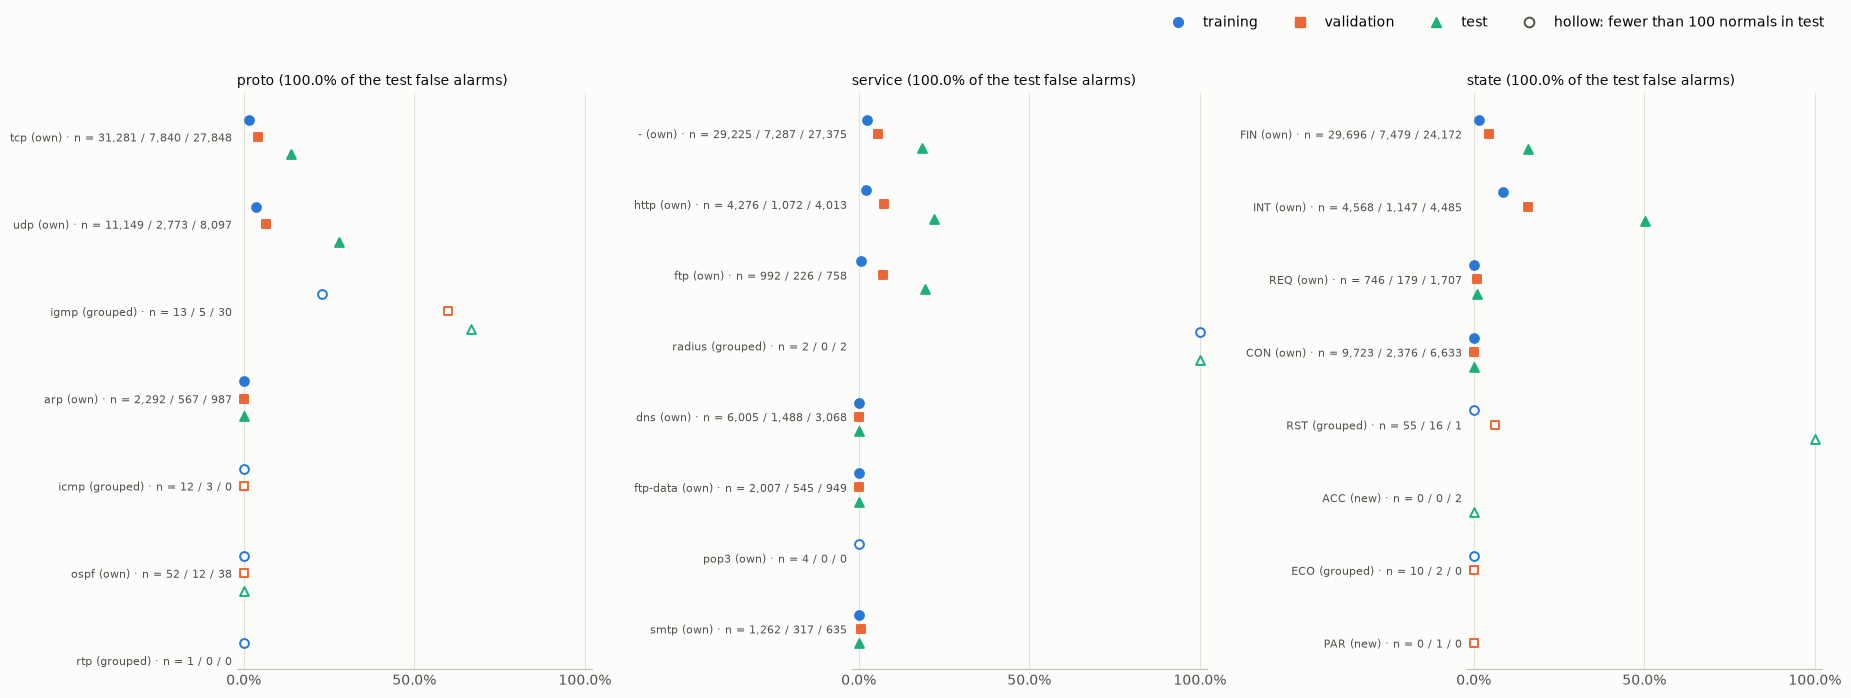

Guardada: artifacts/paper_figures/en/false_alarms_by_category.png
Guardada: artifacts/paper_figures/es/false_alarms_by_category.png


In [17]:
MIN_TEST_NORMALS = 100
TOP_CATEGORIES = 8
IN_TRAINING_EN = {"propia": "own", "agrupada": "grouped", "nueva": "new"}


def draw_false_alarms_by_category(language):
    text = {
        "en": {"splits": ["training", "validation", "test"], "share": "{} ({} of the test false alarms)",
               "hollow": f"hollow: fewer than {MIN_TEST_NORMALS} normals in test"},
        "es": {"splits": ["entrenamiento", "validación", "prueba"], "share": "{} ({} de las falsas alarmas de prueba)",
               "hollow": f"sin relleno: menos de {MIN_TEST_NORMALS} normales en prueba"},
    }[language]
    splits = {split: (label, color, marker) for split, label, color, marker in zip(
        ("train", "validation", "test"), text["splits"], ("#2a78d6", "#eb6834", "#1baf7a"), ("o", "s", "^"))}
    model_rows = by_category[by_category["model"] == "hist_gradient_boosting"]
    columns = sorted(model_rows["column"].unique())
    fig, axes = plt.subplots(1, len(columns), figsize=(6.2 * len(columns), 0.6 * TOP_CATEGORIES + 2.2), facecolor=SURFACE)
    for ax, column in zip(axes, columns):
        rows = model_rows[model_rows["column"] == column].head(TOP_CATEGORIES)
        ax.set_facecolor(SURFACE)
        for position, (_, row) in enumerate(reversed(list(rows.iterrows()))):
            few = row["test_normals"] < MIN_TEST_NORMALS
            for offset, (split, (label, color, marker)) in zip((0.2, 0, -0.2), splits.items()):
                value = row[f"{split}_false_alarm_rate"]
                if pd.isna(value):
                    continue
                ax.scatter(value, position + offset, s=40, marker=marker, color=color,
                           facecolor=SURFACE if few else color, linewidth=1.4, zorder=3,
                           label=label if position == 0 else None)
        status = (lambda s: IN_TRAINING_EN[s]) if language == "en" else (lambda s: s)
        labels = [
            f"{row['category']} ({status(row['in_training'])}) · n = {number(row['train_normals'], 0, language)} / "
            f"{number(row['validation_normals'], 0, language)} / {number(row['test_normals'], 0, language)}"
            for _, row in reversed(list(rows.iterrows()))
        ]
        ax.set_yticks(range(len(rows)), labels, color=INK, fontsize=8)
        share = percent(rows["share_of_test_false_alarms"].sum() * 100, 1, language)
        ax.set_title(text["share"].format(column, share), loc="left", color=INK, fontsize=10)
        ax.xaxis.set_major_formatter(axis_percent(language, 1))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        ax.set_xlim(-0.02, 1.02)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
    handles = [plt.Line2D([], [], marker=marker, linestyle="", markersize=7, color=color) for _, color, marker in splits.values()]
    names = [label for label, _, _ in splits.values()]
    hollow = plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=MUTED, markerfacecolor=SURFACE, markeredgewidth=1.4)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.legend([*handles, hollow], [*names, text["hollow"]], ncol=4, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    return fig


save_both(draw_false_alarms_by_category, "false_alarms_by_category")

### `numeric_differences_normals`: variables numéricas de los normales

Desde `numeric_differences_normals.csv`, como en la sección 6 del notebook 06: para los normales de los grupos `tcp` + `FIN` y `udp` + `INT`, la distancia de Kolmogorov–Smirnov de las 10 variables con mayor diferencia en A (entrenamiento contra prueba) y en B (en prueba, con falsa alarma contra sin ella), con la referencia R (entrenamiento contra validación) de la misma variable en gris.

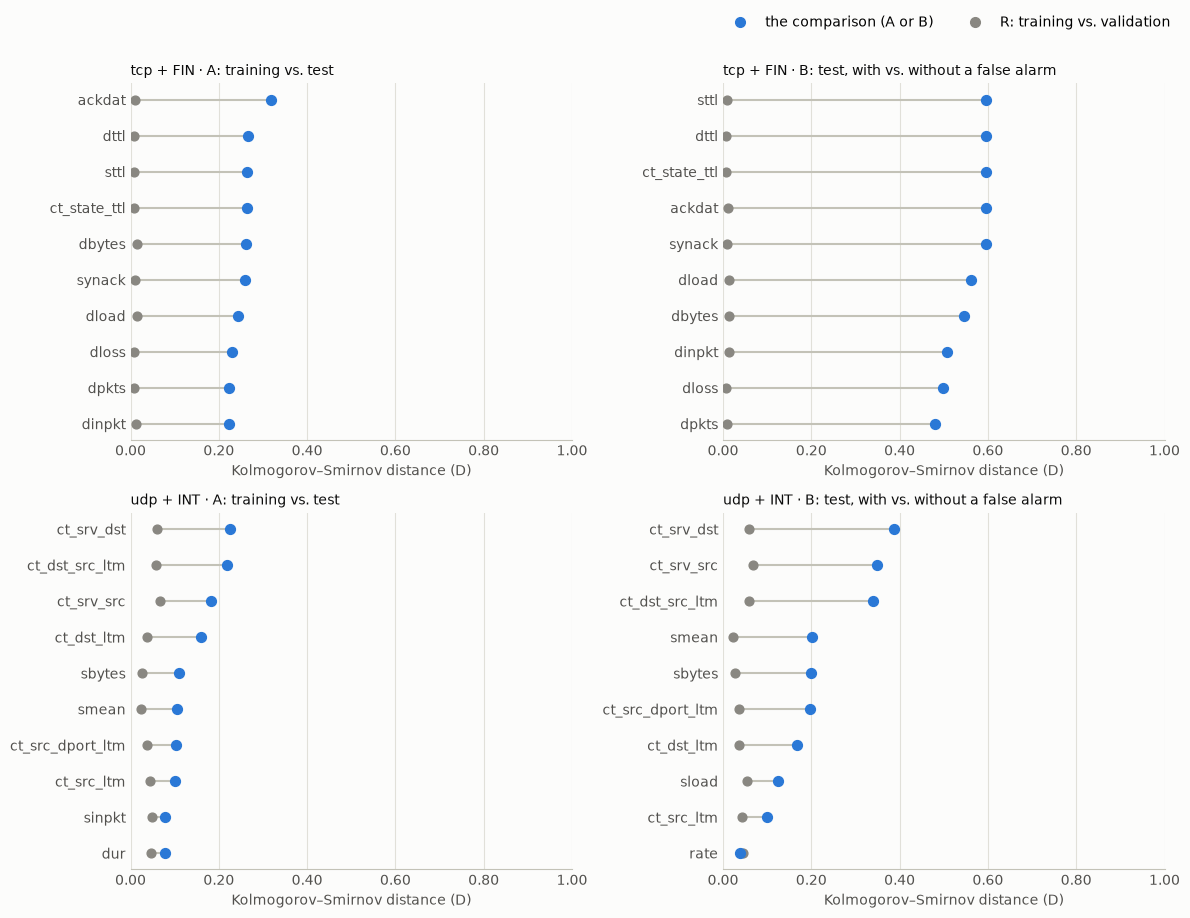

Guardada: artifacts/paper_figures/en/numeric_differences_normals.png
Guardada: artifacts/paper_figures/es/numeric_differences_normals.png


In [18]:
NUMERIC_GROUPS = ["tcp + FIN", "udp + INT"]
TOP_VARIABLES = 10
reference = numeric_table[numeric_table["comparison"] == "R"].set_index(["group", "variable"])["ks_d"]


def draw_numeric_differences_normals(language):
    text = {
        "en": {"titles": {"A": "A: training vs. test", "B": "B: test, with vs. without a false alarm"},
               "x": "Kolmogorov–Smirnov distance (D)", "legend": ["the comparison (A or B)", "R: training vs. validation"]},
        "es": {"titles": {"A": "A: entrenamiento contra prueba", "B": "B: prueba, con falsa alarma contra sin ella"},
               "x": "distancia de Kolmogorov–Smirnov (D)", "legend": ["la comparación (A o B)", "R: entrenamiento contra validación"]},
    }[language]
    comparison_color, reference_color = "#2a78d6", "#898781"
    fig, axes = plt.subplots(len(NUMERIC_GROUPS), 2, figsize=(12, 4.6 * len(NUMERIC_GROUPS)), facecolor=SURFACE)
    for row_axes, group in zip(axes, NUMERIC_GROUPS):
        for ax, comparison in zip(row_axes, ("A", "B")):
            rows = numeric_table[(numeric_table["group"] == group) & (numeric_table["comparison"] == comparison)].nlargest(TOP_VARIABLES, "ks_d")
            ax.set_facecolor(SURFACE)
            for position, (_, row) in enumerate(reversed(list(rows.iterrows()))):
                r = reference[(group, row["variable"])]
                ax.plot([r, row["ks_d"]], [position, position], color=AXIS, linewidth=1.5, zorder=1)
                ax.scatter(r, position, s=40, color=reference_color, zorder=2)
                ax.scatter(row["ks_d"], position, s=50, color=comparison_color, zorder=3)
            ax.set_yticks(range(len(rows)), list(rows["variable"])[::-1], color=INK)
            ax.set_xlim(0, 1)
            ax.xaxis.set_major_formatter(axis_number(language, 2))
            ax.set_xlabel(text["x"], color=MUTED)
            ax.set_title(f"{group} · {text['titles'][comparison]}", loc="left", color=INK, fontsize=10)
            ax.grid(axis="x", color=GRID, linewidth=0.8)
            ax.set_axisbelow(True)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
            ax.spines["bottom"].set_color(AXIS)
            ax.tick_params(colors=MUTED, length=0)
    handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=c) for c in (comparison_color, reference_color)]
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.legend(handles, text["legend"], ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    return fig


save_both(draw_numeric_differences_normals, "numeric_differences_normals")

## 8. Cierre

Las 16 figuras quedan en `artifacts/paper_figures/en/` y `artifacts/paper_figures/es/`, a 300 ppp. El origen de cada una y cómo se regeneran están en `artifacts/paper_figures/README.md`. La selección final para el artículo se hace al escribirlo.

In [19]:
for language in PAPER_FIGURE_LANGUAGES:
    names = sorted(p.stem for p in (PAPER_FIGURES_DIR / language).glob("*.png"))
    print(f"{language}: {len(names)} figuras")
assert {p.name for p in (PAPER_FIGURES_DIR / "en").glob("*.png")} == {p.name for p in (PAPER_FIGURES_DIR / "es").glob("*.png")}

en: 16 figuras
es: 16 figuras
